# PIR and mmWAVE Sensor Analysis

Analyze the false positive and false negative rates to develop a rule-based algorithm. Press `shift + enter` to run each cell.

In [1]:
import numpy as np

import utils

## Settings

In [2]:
# Recording (folder containing occ.csv and meta.json)
RECORDING_PATH = "recordings/desk_work"

## Analyze Raw Sensor Data

Downsample 10 Hz sample readings to 1 Hz, plot the raw sensor readings to see false positives and false negatives, and then calculate the hit/false alarm rates.

In [3]:
# Load raw sample data
rec, meta = utils.load_recording(RECORDING_PATH)
dt_log = meta["config"]["sample_interval_us"] * 1e-6
print(f"Period: {dt_log:.2f} sec")
print(f"Num samples: {rec['t'].shape}")

Period: 0.10 sec
Num samples: (9001,)


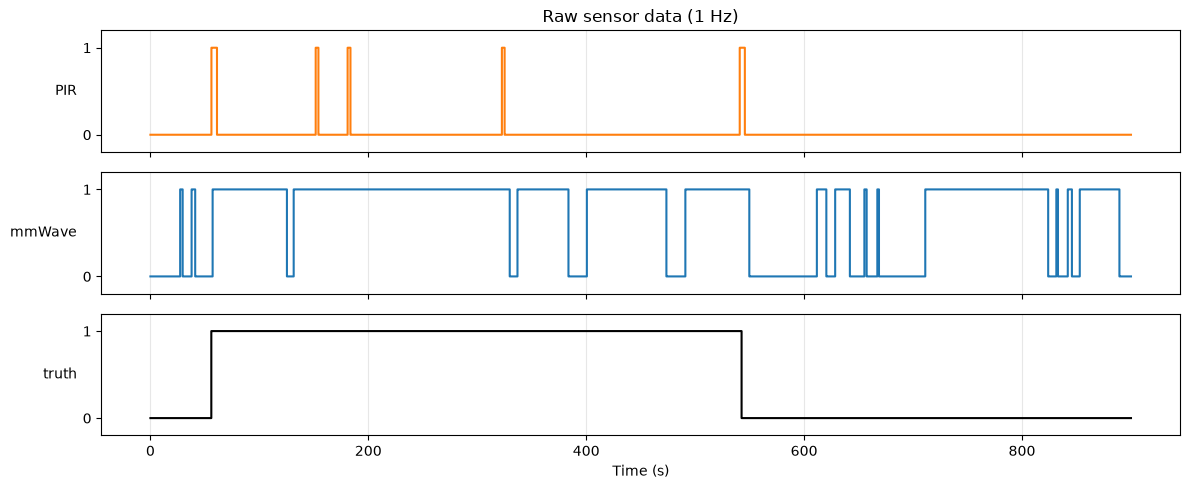

In [4]:
# Plot ground truth vs. raw sensor readings
utils.plot_timeline(
    rec["t"], 
    [
        ("PIR", rec["pir"], "tab:orange"),
        ("mmWave", np.clip(rec["mmwave"], 0, None), "tab:blue"),
        ("truth", rec["truth"], "k"),
    ], 
    title="Raw sensor data (1 Hz)",
)

In [5]:
# Print confusion matrix for PIR sensor
cm_pir = utils.confusion_matrix(rec["pir"], rec["truth"])
print("Confusion matrix for PIR")
utils.print_confusion_matrix(cm_pir)
print("Error rates for PIR")
utils.print_error_rates(cm_pir)

Confusion matrix for PIR
                 sensor=1  sensor=0
  truth=occupied      144      4723
  truth=empty          30      4104

Error rates for PIR
                 sensor=1  sensor=0
  truth=occupied    0.030     0.970    (TPR, FNR)
  truth=empty       0.007     0.993    (FPR, TNR)



In [6]:
# Print confusion matrix for PIR sensor
cm_pir = utils.confusion_matrix(rec["mmwave"], rec["truth"])
print("Confusion matrix for mmWave")
utils.print_confusion_matrix(cm_pir)
print("Error rates for mmWave")
utils.print_error_rates(cm_pir)

Confusion matrix for mmWave
                 sensor=1  sensor=0
  truth=occupied     4379       488
  truth=empty        1930      2204

Error rates for mmWave
                 sensor=1  sensor=0
  truth=occupied    0.900     0.100    (TPR, FNR)
  truth=empty       0.467     0.533    (FPR, TNR)



## Simple Rule-Based Fusion

The PIR sensor has a low FPR (but high FNR), and the mmWave sensor has a low FNR (but high FPR), we can design a simple trigger fusion algorithm: if the PIR senses motion, then it's a high probability that someone is in the room, so we set the occupancy detection flag. So long as the PIR or mmWave sensors detect something, the flag is kept high. If neither sensor detects anything for 5 seconds, then we set the flag to low, which means there is a high probability that the room is empty.

In [7]:
def rule_based_fusion(t, pir, mmwave, timeout_s):
    """
    Simple rule-based fusion: PIR marks the room as occupied. Either PIR or
    mmWave detection can keep the occupied flag high. If neither sensor
    detects presence, then the flag will drop after `timeout_s` seconds.
    """
    fused = np.zeros(len(t), dtype=int)
    occupied = False
    t_evidence = -np.inf

    # Go through each detection
    for i in range(len(t)):
        # PIR sensor can raise the flag or keep it high
        if pir[i] == 1:
            occupied = True
            t_evidence = t[i]

        # mmWave sensor can only keep flag high        
        elif mmwave[i] == 1:
            t_evidence = t[i]

        # Mark room empty if no detections from either sensor for a while
        if occupied and (t[i] - t_evidence > timeout_s):
            occupied = False

        # Mark room as occupied or empty
        fused[i] = int(occupied)

    return fused

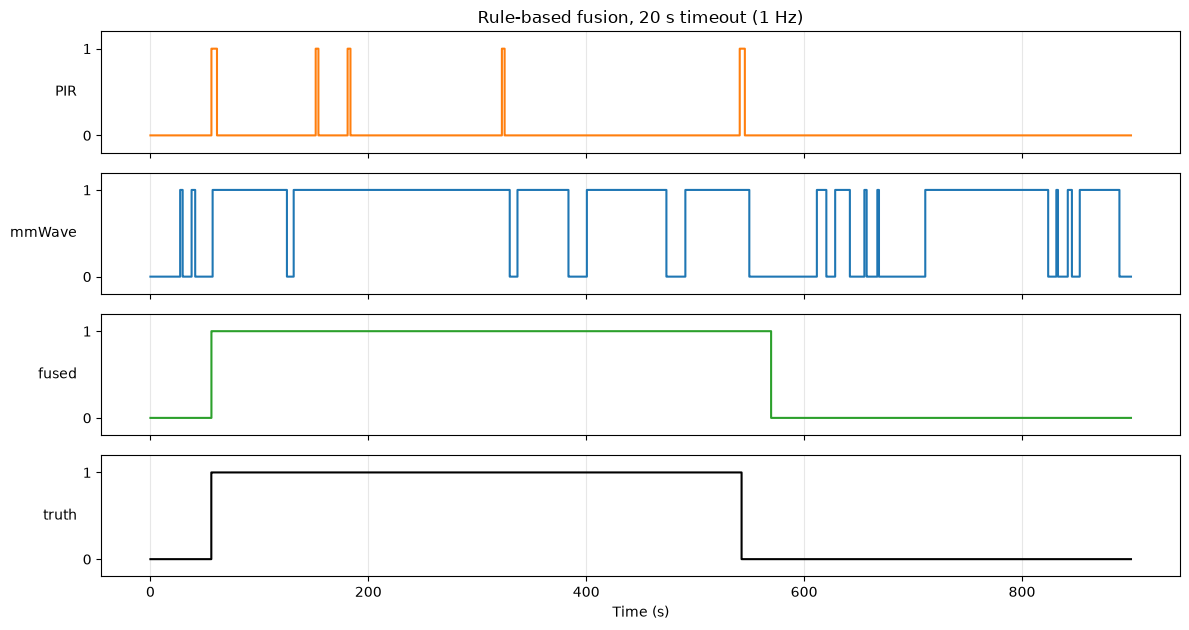

In [8]:
# No detections for this long means the room is empty (adjust as needed)
TIMEOUT_S = 20.0

# Perform our rule-based fusion on the readings
fused = rule_based_fusion(rec["t"], rec["pir"], rec["mmwave"], TIMEOUT_S)

# Plot fused output with our other graphs
utils.plot_timeline(
    rec["t"],
    [
        ("PIR", rec["pir"], "tab:orange"),
        ("mmWave", np.clip(rec["mmwave"], 0, None), "tab:blue"),
        ("fused", fused, "tab:green"),
        ("truth", rec["truth"], "k"),
    ],
    title=f"Rule-based fusion, {TIMEOUT_S:.0f} s timeout (1 Hz)",
)